In [94]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict
from IPython.display import Image, display
from langchain_core.runnables.graph import MermaidDrawMethod

In [ ]:
from typing_extensions import TypedDict

class NewState(TypedDict):
    temp: float
    ctype: str
    newtemp: float
    msg: str

class StateUpdate(TypedDict, total=False):
    newtemp: float
    msg: str

In [96]:
def show_temp(state: NewState) -> StateUpdate:
  temp = state['temp']
  prompt = f'your temperature is: {temp}'

  return{'msg' : prompt}

In [97]:
def check_temp(state: NewState) -> StateUpdate:
  ctype = state['ctype']
  temp = state['temp']

  if(ctype == 'celsius'):
    newt = (temp * 9/5) + 32
  elif(ctype == 'fahrenheit'):
    newt = (temp - 32) * 5/9
  else:
    newt = 000
    
  return {'newtemp': newt}

In [98]:
graph = StateGraph(NewState)
graph.add_node('show_temp',show_temp)
graph.add_node('check_temp',check_temp)

graph.add_edge(START,'show_temp')
graph.add_edge('show_temp','check_temp')
graph.add_edge('check_temp',END)
workflow=graph.compile()

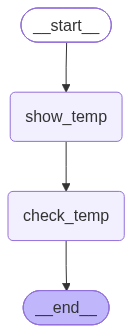

In [99]:
workflow

In [100]:
initial = {
  "temp": 42,
  "ctype": "fahrenheit",
  "newtemp": 0.0,
  "msg": ""
}

result = workflow.invoke(initial)
print(result)

{'temp': 42, 'ctype': 'fahrenheit', 'newtemp': 5.555555555555555, 'msg': 'your temperature is: 42'}
